In [3]:
from pathlib import Path
import mne
import numpy as np
import matplotlib.pyplot as plt
project_root = Path.cwd().parent
eeg_file = project_root / "data" / "raw" / "chb01" / "chb01_03.edf"
print(eeg_file)
print("Exists:", eeg_file.exists()) #checks if chb01_03 can be read

raw = mne.io.read_raw_edf(
    eeg_file,
    preload=True,
    verbose=False
)


sfreq = raw.info["sfreq"]

print(raw)
print("Sampling frequency:", sfreq)
print("Number of channels:", len(raw.ch_names))

c:\seizure-detection-ML-project\data\raw\chb01\chb01_03.edf
Exists: True
<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>
Sampling frequency: 256.0
Number of channels: 23


C:\Users\rahma\AppData\Local\Temp\ipykernel_12764\1894745312.py:10: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(


Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


C:\Users\rahma\AppData\Local\Temp\ipykernel_12764\715180028.py:13: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  psd.plot()


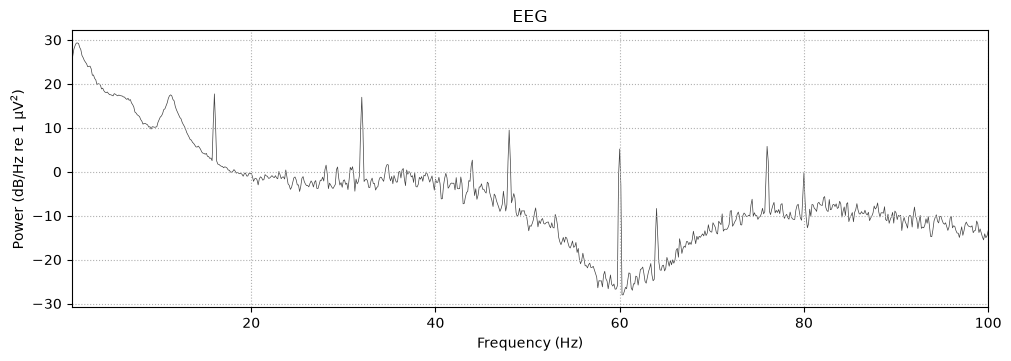

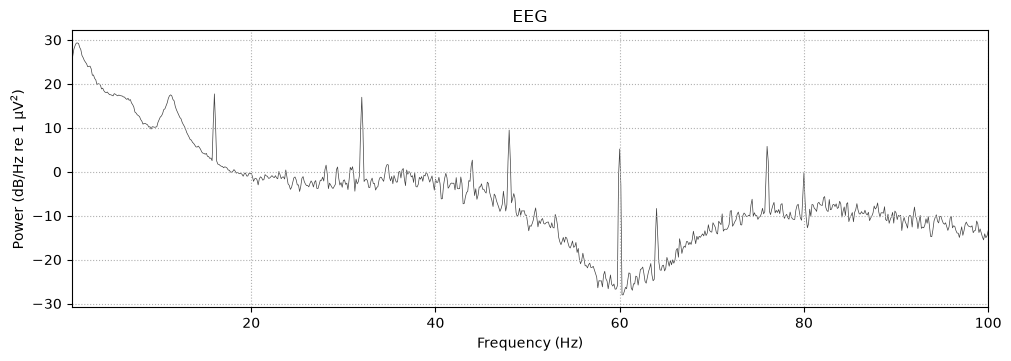

In [ ]:
#Will filter EEG data to remove unwanted contentlike baseline drift, 60Hz electrical noise
#&hgiher freq electrode noise

raw_filtered = raw.copy()
#psd = Power Spectral Density, measurs power distibution across diff. freqs
psd = raw.compute_psd(
    picks=["FP1-F7"], 
    fmin=0.5, 
    fmax=100, 
    n_fft=2048
)

psd.plot()

In [ ]:
#Important to notice the spike at 60Hz, so should apply a notch filter to remove 60Hz noise
#0.5 - 40Hz band pass filter:
    #High pass at 0.5 Hz
    #-> removes freq below 0.5 Hz

    #Low pass at 40 Hz
    #-> removes freq above 40 Hz
    #->Therefore also removes the 60Hz noise spike
raw_filtered.filter(
    l_freq=0.5,
    h_freq=40,
    picks=["FP1-F7"]
)



Filtering a subset of channels. The highpass and lowpass values in the measurement info will not be updated.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1691 samples (6.605 s)



<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


C:\Users\rahma\AppData\Local\Temp\ipykernel_12764\1893624696.py:9: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  filtered_psd.plot()


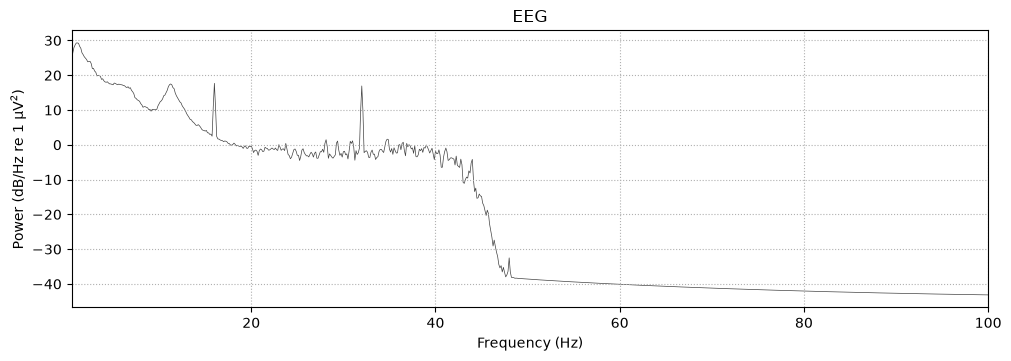

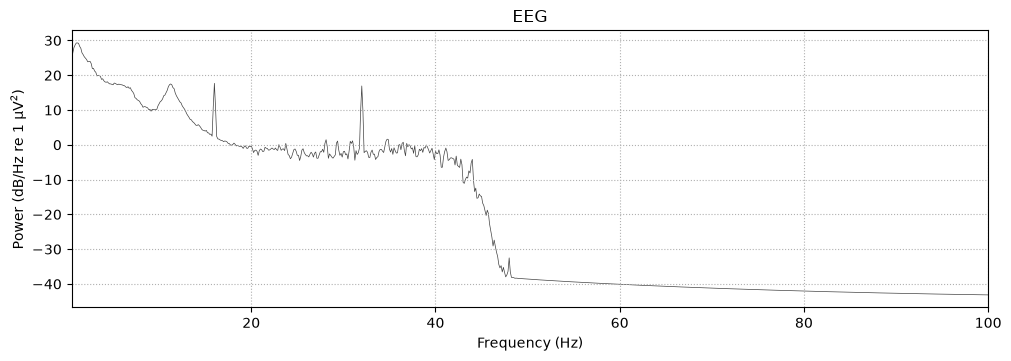

In [7]:
#Checking if filter notch worked:
filtered_psd = raw_filtered.compute_psd(
    picks=["FP1-F7"],
    fmin=0.5,
    fmax=100,
    n_fft=2048
)

filtered_psd.plot()

In [8]:
start_time = 0
end_time = 5
start_sample = int(start_time * sfreq)
end_sample = int(end_time * sfreq)

raw_data, raw_times = raw.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
raw_uv = raw_data[0] * 1e06

filtered_data, filtered_times = raw_filtered.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
filtered_uv = filtered_data[0] * 1e06

print(raw_uv.shape)
print(filtered_uv.shape)
print(raw_uv[:5])
print(filtered_uv[:5])


(1280,)
(1280,)
[-17.77777778   0.1953602    0.1953602    0.58608059   0.1953602 ]
[5.08219768e-15 1.25844015e+01 1.98735059e+01 2.03254785e+01
 1.69195167e+01]


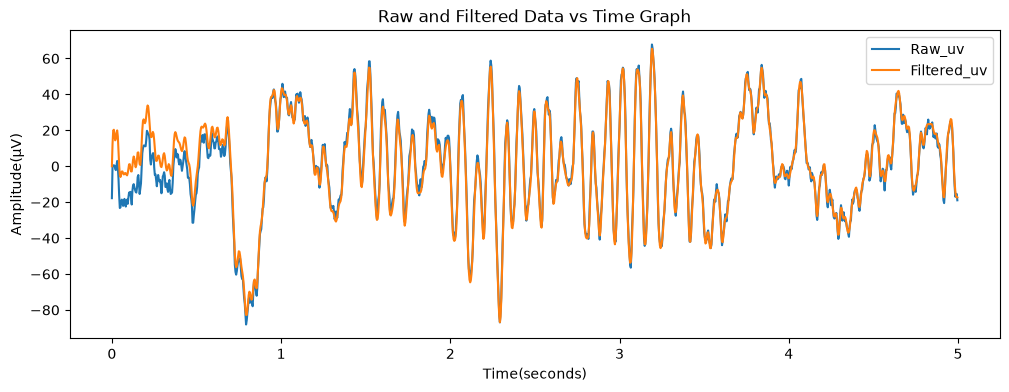

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(raw_times, raw_uv, label=("Raw_uv"))
plt.plot(filtered_times, filtered_uv, label=("Filtered_uv"))
plt.xlabel("Time(seconds)")
plt.ylabel(("Amplitude(µV)"))
plt.title("Raw Vs. Filtered FP1-F7 EEG")
plt.legend()
plt.show()


In [ ]:
raw_std = np.std(raw_uv)
filtered_std = np.std(filtered_uv)

raw_rms = np.sqrt(np.mean(raw_uv**2))
filtered_rms = np.sqrt(np.mean(filtered_uv**2))

raw_ptp = np.ptp(raw_uv)
filtered_ptp = np.ptp(filtered_uv)

print(raw_std, raw_rms, raw_ptp)
print(filtered_std, filtered_rms, filtered_ptp)




27.234515605067216 27.238121948168022 155.89743589743588
26.99604493204598 27.026887917813013 152.25249283140823


In [14]:
start_time_seizure = 3000
end_time_seizure = 3005

start_sample = int(start_time_seizure * sfreq)
end_sample = int(end_time_seizure * sfreq)

raw_data, raw_times = raw.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
raw_uv = raw_data[0] * 1e06

filtered_data, filtered_times = raw_filtered.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
filtered_uv = filtered_data[0] * 1e06

print(raw_uv.shape)
print(filtered_uv.shape)
print(raw_uv[:5])
print(filtered_uv[:5])


(1280,)
(1280,)
[-45.51892552 -52.55189255 -56.45909646 -51.77045177 -67.78998779]
[-34.27365027 -36.94981259 -40.99501699 -46.16648149 -50.9955002 ]


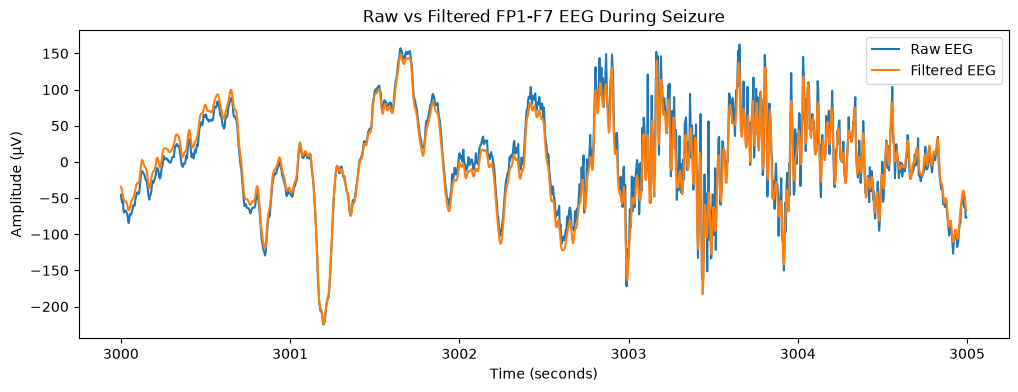

In [15]:
plt.figure(figsize=(12, 4))

plt.plot(raw_times, raw_uv, label="Raw EEG")
plt.plot(filtered_times, filtered_uv, label="Filtered EEG")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title("Raw vs Filtered FP1-F7 EEG During Seizure")
plt.legend()

plt.show()

In [16]:
raw_std = np.std(raw_uv)
filtered_std = np.std(filtered_uv)

raw_rms = np.sqrt(np.mean(raw_uv**2))
filtered_rms = np.sqrt(np.mean(filtered_uv**2))

raw_ptp = np.ptp(raw_uv)
filtered_ptp = np.ptp(filtered_uv)

print(raw_std, raw_rms, raw_ptp)
print(filtered_std, filtered_rms, filtered_ptp)




65.6132599760385 65.66466193146128 387.2039072039072
63.08862509595779 63.090039599586476 372.5953694522716
